# Batter wOBA Projection

By Simon Todreas

This project was an assignment that asked me to project wOBA for MLB batters in the first half of 2026. I was provided biographical data and player statistics at a plate appearance level from 2024 and 2025 (each broken up by first half vs second half) via csv. This data resembled but did not perfectly replicate actual MLB data, so I have replaced the provided data with real data from pybaseball, replicated to the same stage I had in the original project. From there, my methodology is unchanged. In the future, I may generalize this model to include more data and offer more relevant projections than simply first-half 2026, but for now that is what the scope is limited to.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import data
import model as M
import tuning as Tn
import evaluate as E

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

---
## Data

The original data was provided via csv. This replication uses Statcast and Baseball Reference data from the pybaseball package.

In [2]:
statcast = data.load_statcast('2024-03-01', '2025-10-30')
pa_counts = data.build_pa()
player_half = data.build_player_half(statcast, pa_counts)
holdout = data.holdout_players()
people = data.build_people(statcast, holdout)

print(f"shapes: player_half {player_half.shape}, holdout {holdout.shape}\n")
player_half.head()

shapes: player_half (2302, 32), holdout (586,)



,BatterID,game_year,season_half,nPA,nBIP,n1B,n2B,n3B,nHR,nOUT,nK,nHBP,nBB,nwOBA,wOBA,nHardHit,nAir,nSwSp,nPull,nPullAir,sumEV,sumEV90,nPitches,nSwings,nWhiffs,nZSwing,nOSwing,nInZone,nOutZone,nZWhiff,nOWhiff,SeasonID
0,682928,2024,1,332,240,47,20,5,13,155,63,6,23,121.301,0.365364,104,145,99,106,50,21281.1,24940.8,1229,668,161,432,236,612,617,72,89,1
1,547989,2024,1,120,86,10,2,0,2,72,28,2,4,19.624,0.163533,29,38,23,25,4,7552.1,8896.7,486,249,74,169,80,246,240,37,37,1
2,677800,2024,1,213,137,28,16,2,6,85,55,0,21,74.709,0.350746,67,83,44,61,30,12311.2,14621.1,846,406,120,295,111,429,417,63,57,1
3,660670,2024,1,222,139,35,8,1,4,91,53,3,27,71.455,0.321869,67,64,44,61,15,12720.5,14992.54,905,425,117,331,94,466,439,76,41,1
4,642715,2024,1,365,244,42,18,0,13,171,77,1,43,116.613,0.319488,94,163,84,101,50,21558.9,25156.4,1436,683,198,494,189,699,737,98,100,1


In the holdout dataset that I will ultimately make predictions on, how many season-halves of data are available for each player?

In [3]:
print("Holdout History by halves:")
print(player_half.groupby("BatterID").size().reindex(holdout).fillna(0)\
      .astype(int).value_counts().sort_index().rename_axis("halves"))

Holdout History by halves:
halves
0     71
1     46
2     76
3     71
4    322
Name: count, dtype: int64


---
## Data Exploration


In [4]:
# Two helpers for this section. wcorr weights a correlation by the target half's denominator, and
# transitions builds the consecutive-half pairs, with the option to set a floor on both
# halves. Which correlations are weighted is noted on each table below.
def wcorr(x, y, w):
    """Correlation of x and y, weighted by w."""
    dx, dy = x - np.average(x, weights=w), y - np.average(y, weights=w)
    return np.average(dx * dy, weights=w) / np.sqrt(
        np.average(dx * dx, weights=w) * np.average(dy * dy, weights=w))

def transitions(floor=0, denom="nPA"):
    """One row per (player, consecutive-half pair): `_p` the prior half, `_t` the target.

    Shifting the prior half's SeasonID (1,2,3,4) forward by one makes it collide with the target's, so
    a simple inner merge does the join, the column alignment, and the drop of any player
    missing either half. Both halves are then held to `floor` in `denom`.
    """
    both = (player_half.assign(SeasonID=player_half.SeasonID + 1)
              .merge(player_half, on=["BatterID", "SeasonID"], suffixes=("_p", "_t"))
              .rename(columns={"SeasonID": "target_half"}))
    return both[(both[f"{denom}_p"] >= floor) & (both[f"{denom}_t"] >= floor)]

transitions(50)[["BatterID", "target_half", "nPA_p", "wOBA_p", "nPA_t", "wOBA_t"]].head()

,BatterID,target_half,nPA_p,wOBA_p,nPA_t,wOBA_t
0,682928,2,332,0.365364,270,0.272152
1,677800,2,213,0.350746,233,0.323197
2,642715,2,365,0.319488,323,0.370560
4,666176,2,250,0.277776,201,0.319179
5,605113,2,151,0.269172,77,0.198260


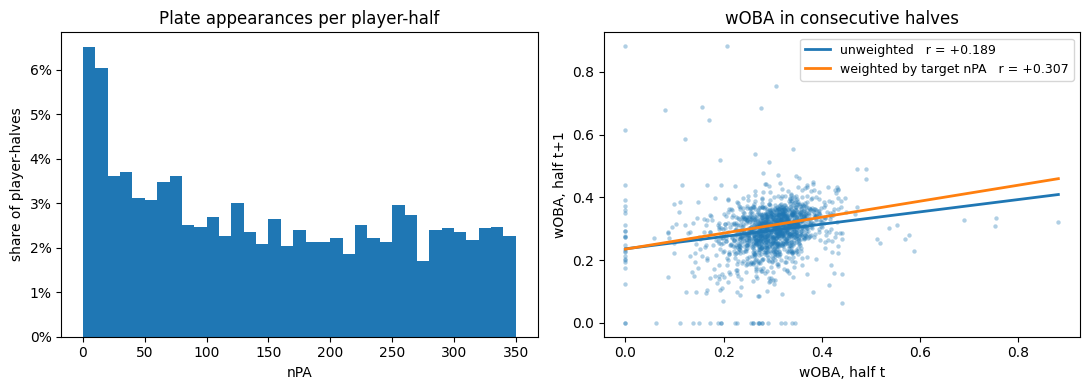

In [5]:
# Left: Histogram of plate appearances by player-half 
# Right: Scatterplot of wOBA in consecutive halves with weighted and unweighted correlations

pairs = transitions()
x, y, w = pairs.wOBA_p.to_numpy(), pairs.wOBA_t.to_numpy(), pairs.nPA_t.to_numpy(float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(player_half.nPA, bins=np.arange(0, 360, 10),
         weights=np.full(len(player_half), 100 / len(player_half)))
ax1.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax1.set(title="Plate appearances per player-half", xlabel="nPA", ylabel="share of player-halves")

ax2.scatter(x, y, s=10, alpha=.35, lw=0)
grid = np.linspace(x.min(), x.max(), 2)
for wt, lab in ((None, "unweighted"), (w, "weighted by target nPA")):
    r = np.corrcoef(x, y)[0, 1] if wt is None else wcorr(x, y, wt)
    beta = np.polyfit(x, y, 1, w=None if wt is None else np.sqrt(wt))
    ax2.plot(grid, np.polyval(beta, grid), lw=2, label=f"{lab}   r = {r:+.3f}")
ax2.legend(fontsize=9)
ax2.set(title="wOBA in consecutive halves", xlabel="wOBA, half t", ylabel="wOBA, half t+1")
fig.tight_layout()
plt.show()

In [6]:
# wOBA correlation, unweighted, by minimum PA and season-half transition

rows = []
for floor in (0, 25, 50, 100, 200):
    steps = transitions(floor)
    parts = [(f"{t - 1} -> {t}", g) for t, g in steps.groupby("target_half")] + [("all", steps)]
    rows += [{"floor (PA, both halves)": floor, "transition": lab,
              "n": len(g), "corr": g.wOBA_p.corr(g.wOBA_t)} for lab, g in parts]
pd.DataFrame(rows).pivot(index="floor (PA, both halves)", columns="transition",
                         values=["n", "corr"]).round(2)

n                         corr                    
transition              1 -> 2 2 -> 3 3 -> 4     all 1 -> 2 2 -> 3 3 -> 4   all
floor (PA, both halves)                                                        
0                        488.0  472.0  490.0  1450.0   0.05   0.23   0.30  0.19
25                       410.0  391.0  408.0  1209.0   0.26   0.37   0.37  0.33
50                       370.0  348.0  366.0  1084.0   0.32   0.36   0.35  0.34
100                      293.0  275.0  282.0   850.0   0.26   0.36   0.36  0.32
200                      159.0  150.0  165.0   474.0   0.30   0.45   0.37  0.37

In [7]:
# Weighted correlations between potential features and outcomes. This provides strong evidence
# in support of features being included in both stages of the model. For example, whiff rate is nearly  
# as highly correlated with next half K as prior half K and that's based on pitches as opposed
# to plate appearances.  
def vs_next(feats, cats, denom, floor):
    """
    Weighted corr of each feature with each category's rate in the FOLLOWING half. Each correlation is 
    computed per transition and averaged.
    """
    steps = [g for _, g in transitions(floor, denom).groupby("target_half")]
    out = {}
    for name, ND in list(feats.items()) + [("own past rate", None)]:
        out[name] = {}
        for c in cats:
            num, den = (f"{c}_p", f"{denom}_p") if ND is None else (f"{ND[0]}_p", f"{ND[1]}_p")
            out[name][c[1:]] = np.mean([
                wcorr((g[num] / g[den]).to_numpy(),
                      (g[f"{c}_t"] / g[f"{denom}_t"]).to_numpy(),
                      g[f"{denom}_t"].to_numpy()) for g in steps])
    return pd.DataFrame(out).T

PAF = {"whiff": ("nWhiffs", "nSwings"), "osw": ("nOSwing", "nOutZone"),
       "zsw": ("nZSwing", "nInZone"), "zone": ("nInZone", "nPitches"),
       "swing": ("nSwings", "nPitches"), "zwhiff": ("nZWhiff", "nZSwing"),
       "owhiff": ("nOWhiff", "nOSwing")}
display(vs_next(PAF, ["nK", "nBB", "nHBP", "nBIP"], "nPA", 50).round(3))

BIPF = {"ev90": ("sumEV90", "nBIP"), "ev": ("sumEV", "nBIP"),
        "hardhit": ("nHardHit", "nBIP"), "air": ("nAir", "nBIP"),
        "pullair": ("nPullAir", "nBIP"), "pull": ("nPull", "nBIP"), "swsp": ("nSwSp", "nBIP")}
display(vs_next(BIPF, ["nHR", "n1B", "n2B", "n3B", "nOUT"], "nBIP", 50).round(3))

,K,BB,HBP,BIP
whiff,0.722,0.065,0.031,-0.650
osw,-0.041,-0.537,-0.019,0.278
zsw,0.094,-0.264,-0.008,0.038
zone,-0.126,-0.028,0.030,0.118
swing,0.009,-0.484,-0.007,0.210
zwhiff,0.668,0.143,0.003,-0.635
owhiff,0.646,0.117,0.062,-0.612
own past rate,0.741,0.570,0.391,0.745


,HR,1B,2B,3B,OUT
ev90,0.527,-0.089,0.279,0.005,-0.380
ev,0.503,-0.068,0.242,-0.010,-0.363
hardhit,0.516,-0.058,0.252,0.001,-0.386
air,0.281,-0.244,0.032,-0.026,0.017
pullair,0.284,-0.284,-0.053,-0.015,0.085
pull,0.249,-0.190,-0.070,-0.001,0.034
swsp,0.074,-0.019,0.068,-0.028,-0.056
own past rate,0.584,0.161,0.124,0.339,0.223


In [8]:
# Key statistics by prior sample size. Across the board, players with less previous experience
# perform worse with a worse wOBA, higher K%, lower BB%, and fewer HRs/BIP. There may be an
# inflection point ~100PA where players begin playing better. It's possible this is the line
# between a regular player and a call-up or fill-in.

prior = (player_half.sort_values("SeasonID").groupby("BatterID").nPA
         .apply(lambda s: s.cumsum().shift(1).fillna(0)).rename("prior_PA"))
ph_d = player_half.join(prior.droplevel(0) if prior.index.nlevels > 1 else prior)
ph_d = ph_d[ph_d.SeasonID > 1]
(ph_d.groupby(pd.cut(ph_d.prior_PA, [-1, 0, 25, 100, 300, 10000],
                     labels=["0", "1-25", "26-100", "101-300", "300+"]), observed=True)
     .apply(lambda d: pd.Series({"player-halves": len(d), "median nPA": d.nPA.median(),
                                 "wOBA": d.nwOBA.sum() / d.nPA.sum(),
                                 "K%": d.nK.sum() / d.nPA.sum(),
                                 "BB%": d.nBB.sum() / d.nPA.sum(),
                                 "HR/BIP": d.nHR.sum() / d.nBIP.sum(),
                                 "EV90": d.sumEV90.sum() / d.nBIP.sum()}),
            include_groups=False).round(3))

,player-halves,median nPA,wOBA,K%,BB%,HR/BIP,EV90
prior_PA,,,,,,,
0,227.0,45.0,0.288,0.259,0.075,0.037,103.577
1-25,102.0,43.0,0.285,0.266,0.076,0.034,102.430
26-100,228.0,55.5,0.287,0.256,0.079,0.035,103.275
101-300,479.0,148.0,0.304,0.232,0.078,0.042,103.647
300+,705.0,249.0,0.324,0.213,0.087,0.049,104.822


---
## Configuration

Each stage has one dictionary that defines its key properties. This dictionary is passed all the way through the modeling process ensuring consistency.

| key | what it declares |
|---|---|
| `cats` | the outcome columns |
| `denom` | the denominator for every outcome and the unit for kappa |
| `features` | candidate → (numerator, denominator), each a plain ratio of pooled counts |
| `feat_cols` | the columns the numerators and denominators are pooled from |
| `phi_grid` | the concentration grid, in that stage's own denominator units |
| `green` | the greenness scale $\nu$, likewise in the stage's own units |

Note: `feat_cols` must never repeat the stage's own category or denominator

In [9]:
TARGET = 5                                     # 2026 1H
FOLDS = (3, 4)                                 # the two scoreable season-halves: 2025 1H and 2025 2H
PA_BINS = [-1, 0, 50, 100, 200, 400, 10000]    # history depth; -1 isolates no-history

# The plate appearance stage:
# Features are mostly related to plate discipline, measured per PITCH.
# There are many more pitches than plate appearances for each hitter, which is the
# main reason a discipline-based prior beats the hitter's own outcome record.
STAGE_PA = {
    "cats":  ["nK", "nBB", "nHBP", "nBIP"],
    "denom": "nPA",
    "features": {
        # feature: (numerator, denominator)
        "whiff":  ("nWhiffs", "nSwings"),
        "zwhiff": ("nZWhiff", "nZSwing"),
        "owhiff": ("nOWhiff", "nOSwing"),
        "osw":    ("nOSwing", "nOutZone"),
        "zsw":    ("nZSwing", "nInZone"),
        "zone":   ("nInZone", "nPitches"),
    },
    "feat_cols": ["nPitches", "nSwings", "nWhiffs", "nInZone", "nOutZone",
                  "nZSwing", "nOSwing", "nZWhiff", "nOWhiff"],
    "phi_grid":  [25, 35, 50, 75, 100, 125, 150, 200, 300, 500],   # swings and pitches
    "green":     25,                                               # plate appearances
}

In [10]:
# The ball in play stage: This is conditional on contact. 
# These features are related to how the ball was hit, largely contact quality.
STAGE_BIP = {
    "cats":  ["nHR", "n1B", "n2B", "n3B", "nOUT"],
    "denom": "nBIP",
    "features": {
        "hardhit": ("nHardHit", "nBIP"),   # EV >= 95
        "air":     ("nAir",     "nBIP"),   # LA >= 10
        "swsp":    ("nSwSp",    "nBIP"),   # LA in [8, 32]
        "pull":    ("nPull",    "nBIP"),   
        "pullair": ("nPullAir", "nBIP"),   
        "ev":      ("sumEV",    "nBIP"),   # mean exit velocity
        "ev90":    ("sumEV90",  "nBIP"),   # 90th-percentile exit velocity
    },
    "feat_cols": ["nHardHit", "nAir", "nSwSp", "nPull", "nPullAir", "sumEV", "sumEV90"],
    "phi_grid":  [10, 20, 30, 40, 50, 75, 100, 150],   # balls in play
    "green":     25,                                   # balls in play
}

STAGES = (STAGE_PA, STAGE_BIP)

In [11]:
# The baseline model: This stage is for a direct shrinkage of wOBA itself, with no
# components nor features. It is a stage dictionary like the others and runs through the
# same code path. nwOBA = wOBA * nPA is a summable weighted count, so it pools and 
# shrinks like the outcome counts do, and `act` is returned as observed wOBA with nPA as the weight.
# This is a higher baseline my model must clear.
#
# Note: The leading "n" is necessary for all categories in "cats"
STAGE_WOBA = {
    "cats": ["nwOBA"], "denom": "nPA",
    "features": {}, "feat_cols": [],
    "phi_grid": [1],   # read as the phi, but inert: with no features nothing consumes it
    "green": 25,       # also inert
}

---
## Features

The model is fitted bottom-up and that starts with the features. First, we must determine which features each category uses. Then we determine how much they are shrunk. Selection comes first because phi is fitted on whichever features survive it. This is only non-circular because the same features are selected across a wide range of phi.

Feature selection is done using greedy forward selection by prior error. Step 0 is the flat league rate, the reference every later step has to beat and what a category keeps if nothing earns its place.

In [12]:
# Selection is invariant to this reference phi from 35 through 500; only at 25 does
# anything move, and that is K's second pick going from zsw to osw.
SELECT_PHI_PA = 100
Tn.feature_selection(player_half, TARGET, SELECT_PHI_PA, STAGE_PA).round(4)

feature                                               mse                        
cat             BB           BIP           HBP             K      BB     BIP     HBP       K
step                                                                                        
0     (league avg)  (league avg)  (league avg)  (league avg)  1.1835  6.1534  0.1194  4.8318
1              osw         whiff        owhiff         whiff  0.8628  4.0128  0.1188  2.8541
2             zone           osw        zwhiff           zsw  0.8130  3.2455  0.1187  2.7481
3           zwhiff           zsw          zone          zone  0.7966  3.2128  0.1186  2.6946
4            whiff        owhiff         whiff           osw  0.7900  3.2104  0.1184  2.6856
5           owhiff        zwhiff           osw        zwhiff  0.7895  3.2086  0.1183  2.6769
6              zsw          zone           zsw        owhiff  0.7895  3.2049  0.1183  2.6682

In [13]:
# The conclusion of the table above. Two or three features carry every category that takes any, and
# it's worth noting that the marginal correlations do not perfectly translate. For example,
# zwhiff and owhiff correlate +0.67 and +0.65 with next-half K% individually and add virtually
# nothing once whiff is in.
#
# Also of note, HBP keeps the flat league prior: all six features together move it < 1%, 
#
# "green" is appended to every category that takes features. It is NOT selected, because it is
# not a statistical measurement. Instead it is a property of the denominator, and it corrects
# the baseline rather than ranking hitters. Its coefficients are below.
FEAT_USE_PA = {"K":   ["whiff", "zsw", "zone", "green"],
               "BB":  ["osw", "zone", "green"],
               "HBP": [],
               "BIP": ["whiff", "osw", "zsw", "green"]}

In [14]:
SELECT_PHI_BIP = 40
Tn.feature_selection(player_half, TARGET, SELECT_PHI_BIP, STAGE_BIP).round(3)

feature                                                            mse                            
cat             1B            2B            3B            HR           OUT     1B     2B     3B     HR    OUT
step                                                                                                         
0     (league avg)  (league avg)  (league avg)  (league avg)  (league avg)  1.883  0.587  0.058  0.863  2.717
1          pullair          ev90          swsp          ev90          ev90  1.761  0.554  0.058  0.644  2.389
2             swsp          pull          pull           air          swsp  1.748  0.550  0.058  0.552  2.370
3              air          swsp           air          pull       pullair  1.729  0.549  0.058  0.535  2.349
4             ev90           air            ev       hardhit       hardhit  1.718  0.549  0.058  0.528  2.337
5             pull       pullair       hardhit          swsp           air  1.717  0.549  0.058  0.519  2.336
6          hardhit       hardhit          ev90            ev          pull  1.717  0.548  0.058  0.519  2.335
7               ev            ev       pullair       pullair            ev  1.720  0.551  0.058  0.520  2.347

Note:
Every BIP category's first pick holds from phi = 20 through 100, which brackets the 40 that gets fitted. Every pick below that is the same at 20 and at 40. Outside that range it drifts but the churn is between near-collinear contact-quality measures, so the picks below are simply the ones the fitted phi gives.

In [15]:
FEAT_USE_BIP = {"HR":  ["ev90", "air", "green"],
               "1B":  ["pullair", "green"],
               "2B":  ["ev90", "green"],
               "3B":  [],
               "OUT": ["ev90", "green"]}

FEATS = (FEAT_USE_PA, FEAT_USE_BIP)

### $\varphi$ — how much a feature is shrunk

A discipline rate is itself an estimate, so it is shrunk toward the league value before it is allowed to inform anything. The model fits phi on a grid over the fitting halves, minimizing the prior's own error. The surfaces below show that fit, expressed as percent above each column's minimum.

Importantly: the features come from the prior halves and the outcome from the target half, so their noise is independent and less shrinkage cannot flatter itself the way it would in an ordinary in-sample fit.

Additionally, phi cannot be 0 because it is undefined. Seven hitters with a prior half have no out-of-zone swing at all in their pooled history, so `owhiff` would be 0/0 for them, and every hitter with no prior half has a zero denominator on all six features.

Note: The surface is more insightful than the minimum. Both stages are nearly flat, showing the lack of importance of a precise phi

In [16]:
# The two stages carry different grids because phi is in each stage's denominator units:
# swings and pitches at the PA stage, balls in play at the BIP stage.
pd.concat({"PA": Tn.phi_surface(player_half, TARGET, FEAT_USE_PA, STAGE_PA),
           "BIP": Tn.phi_surface(player_half, TARGET, FEAT_USE_BIP, STAGE_BIP)},
          names=["stage", "phi"]
          )[["TOTAL"]].round(2).rename(columns={"TOTAL": "% above own minimum"})

% above own minimum
stage phi                     
PA    25                  2.11
      35                  1.36
      50                  0.69
      75                  0.16
      100                 0.00
      125                 0.01
      150                 0.12
      200                 0.47
      300                 1.36
      500                 3.08
BIP   10                  0.47
      20                  0.09
      30                  0.01
      40                  0.00
      50                  0.02
      75                  0.11
      100                 0.23
      150                 0.47

---
## The fit

Three parameters per stage, nested because each changes the environment the next one sees: **phi → beta → kappa**. Making the prior informative raises kappa several-fold, so beta has to be settled before fitting kappa.

Of note, a parameter for target T sees only targets strictly before T. This is enforced through the fitting_set function. 

In [17]:
# Phis match the surface shown above
params = tuple(Tn.fit_all(player_half, TARGET, fu, st) for fu, st in zip(FEATS, STAGES))
params_PA, params_BIP = params

print(f"phi: PA stage {params_PA.phi} swings/pitches, BIP stage {params_BIP.phi} balls in play")

phi: PA stage 100 swings/pitches, BIP stage 40 balls in play


### kappa, and the only fair way to read it

kappa is in denominator units, so 439 plate appearances and 480 balls in play are not comparable quantities of evidence. The implied weight $n_i/(n_i+\kappa_c)$ at the median hitter is unit-free so we'll use that as a comparison: the median hitter keeps ~56% of his own strikeout record, ~41% of his home runs, and ~16% of his singles.

Notably, neither the implied weight nor kappa can be read as evidence about how much of a half is luck. $\mu$ contains the hitter's own record at corr ≈ 0.75–0.80, so kappa is a fitted regularization strength, not a prior sample size.

Also of interest, the spread across the contact split — 425 for triples to 2166 for doubles — proves that rare and unreliable are not the same thing: triples are a 0.5% event and get the lowest kappa of the five, because the between-player spread in triples is likely speed, and speed is a real skill.

In [18]:
pd.concat([E.shrinkage_table(player_half, TARGET, params_PA, STAGE_PA, holdout),
           E.shrinkage_table(player_half, TARGET, params_BIP, STAGE_BIP, holdout)],
          keys=["PA", "BIP"], names=["stage", "cat"]
          ).round({"kappa": 1, "median history": 3, "implied weight": 3})

kappa                 features units  median history  implied weight
stage cat                                                                       
PA    K     392.2  whiff, zsw, zone, green   nPA           500.0           0.560
      BB    528.7         osw, zone, green   nPA           500.0           0.486
      HBP   360.1            (league rate)   nPA           500.0           0.581
      BIP   483.7   whiff, osw, zsw, green   nPA           500.0           0.508
BIP   HR    479.7         ev90, air, green  nBIP           334.0           0.410
      1B   1732.8           pullair, green  nBIP           334.0           0.162
      2B   2165.7              ev90, green  nBIP           334.0           0.134
      3B    424.8            (league rate)  nBIP           334.0           0.440
      OUT  1468.0              ev90, green  nBIP           334.0           0.185

In [19]:
# Table of Betas for every outcome.
#
# Green is what the model applies to a debutant:
# Thin-history hitters strike out more, put fewer balls in play, and hit for less power than 
# the league average rate they would otherwise receive.
#
# Note: HBP and 3B are absent because they take no features and thus have no beta at all. They
# keep the flat league rate, and serve as the model's two controls.
pd.concat([E.beta_table(params_PA), E.beta_table(params_BIP)],
          keys=["PA", "BIP"], names=["stage", "cat", "term"]).round(3)

coef
stage cat term           
PA    K   const    -2.878
          whiff     5.649
          zsw      -1.146
          zone      1.921
          green     0.233
      BB  const     1.581
          osw      -5.617
          zone     -4.800
          green    -0.126
      BIP const     0.852
          whiff    -4.869
          osw       2.425
          zsw       0.679
          green    -0.135
BIP   HR  const   -19.206
          ev90      0.135
          air       3.646
          green    -0.158
      1B  const    -1.075
          pullair  -1.660
          green     0.040
      2B  const    -6.838
          ev90      0.040
          green    -0.029
      OUT const     4.295
          ev90     -0.034
          green     0.023

---
## 2026 1H projection — the submission

The two stages roll up to a per-plate-appearance outcome distribution:

$$p_K,\; p_{BB},\; p_{HBP} \;\text{ from the PA stage}
\qquad
p_x = \pi_{BIP}\,\psi_x \quad x \in \{HR, 1B, 2B, 3B, OUT\}$$

so the eight probabilities sum to 1 by construction. K and OUT carry wOBA weight zero and never reach the numerator.

Both stages are predicted on the same player spine, which is what puts them on `build_pairs`' production path. This ensures that every player, regardless of previous playing time, receives a prediction.

In [20]:
# Predictions for T = 5 (target half 2026 1H).
pred_5 = E.compose_woba(player_half, TARGET, params, STAGES, holdout).droplevel("target_half")

submission = holdout.to_frame(index=False).join(pred_5["pred_wOBA"], on="BatterID")
submission.to_csv("predictions.csv", index=False)
assert len(submission) == len(holdout) and submission["pred_wOBA"].notna().all()

# Hitters with no history land on mu at both stages, so they receive the same projection
w = pred_5["pred_wOBA"]
with_history = M.build_history(player_half, TARGET, ["nPA"]).index
groups = {"no prior half": w.index.difference(with_history),
          "one or more prior halves": w.index.intersection(with_history),
          "every holdout hitter": w.index}
assert w.loc[groups["no prior half"]].nunique() == 1

rows = []
for name, idx in groups.items():
    v = w.loc[idx]
    rows.append({"group": name, "hitters": len(v), "mean": v.mean(),
                 "sd": v.std(), "min": v.min(), "max": v.max()})
pd.DataFrame(rows).set_index("group").round(3)

,hitters,mean,sd,min,max
group,,,,,
no prior half,71,0.286,0.000,0.286,0.286
one or more prior halves,515,0.306,0.028,0.239,0.451
every holdout hitter,586,0.303,0.027,0.239,0.451


In [21]:
# Note: every outcome probability is strictly positive by construction under the logit link
pred_5[["p_" + c for c in E.OUTCOMES]].agg(["min", "max"]).T.round(4)

,min,max
p_K,0.0513,0.3895
p_BB,0.0362,0.1723
p_HBP,0.0027,0.0357
p_HR,0.0043,0.0790
p_1B,0.0966,0.2039
p_2B,0.0305,0.0580
p_3B,0.0010,0.0169
p_OUT,0.3230,0.6318


In [22]:
# Projected spread is a little over half the observed spread of a played half (.046 at 100+ PA).
# That is expected behavior because an observed half is talent plus sampling noise, and a projection 
# carries only the former.
played = player_half.loc[(player_half["SeasonID"] == 4) & (player_half["nPA"] >= 100), "wOBA"]
pd.DataFrame({"projected 2026 1H": w.describe(), "observed 2025 2H, 100+ PA": played.describe()}).round(3)

,projected 2026 1H,"observed 2025 2H, 100+ PA"
count,586.000,350.000
mean,0.303,0.314
std,0.027,0.046
min,0.239,0.179
25%,0.286,0.284
50%,0.297,0.314
75%,0.320,0.346
max,0.451,0.467


---
## Validation

Expanding window: For target half $T$ every parameter is strictly fit on halves at or before $T-1$. Only two halves are scoreable, 2025 1H and 2025 2H. 

Notably, two folds is the binding constraint on every claim in this project. Differences under ~2% are inside what a single fold moves, and several comparisons had their fold winners disagree. 

Also note that the loss is PA-weighted MSE on observed wOBA, ×1000. The weighting is necessary because playing time varies by an order of magnitude across half-seasons: the median half is 147 PA and the 10th percentile is 14, so an unweighted metric would be dominated by rows carrying almost no information. Pooled over the three half-to-half transitions, wOBA correlates 0.19 across all hitters and 0.34 among those with 50+ PA in both halves. 

In [23]:
# The same fit, once per scoreable fold, and the floor beside it. The floor runs through
# the same code path so it is on equal footing to the component model.
fit_by_T = {t: tuple(Tn.fit_all(player_half, t, fu, st) for fu, st in zip(FEATS, STAGES))
            for t in FOLDS}
model = E.project(player_half, FOLDS, fit_by_T, STAGES)["pred_wOBA"]

floor_p = {t: Tn.fit_all(player_half, t, Tn.no_features(STAGE_WOBA["cats"]), STAGE_WOBA)
           for t in FOLDS}
floor = E.project_stage(player_half, FOLDS, floor_p, STAGE_WOBA)["wOBA"]

actual = E.observed(player_half, FOLDS)
# Control 1: last half's league wOBA
lg = {t: M.league_rates(player_half, t, ["nwOBA"], "nPA")["nwOBA"] for t in FOLDS}
league = pd.Series(actual.index.get_level_values("target_half").map(lg), index=actual.index)

# Control 2: the hitter's own pooled wOBA with no shrinkage 
def own_wOBA(t):
    """Pooled wOBA over every half before t, unshrunk. No history gets the league value.
    """
    p = M.build_pairs(player_half, t, STAGE_WOBA["phi_grid"][0], STAGE_WOBA)
    p = p.set_index(["BatterID", "target_half"])
    return (p["y_p"] / p["n_p"]).fillna(p["league_rate"])

own = pd.concat([own_wOBA(t) for t in FOLDS])

preds = pd.DataFrame({"league average": league,
                      "own wOBA, unshrunk": own,
                      "direct shrinkage of wOBA (the floor)": floor,
                      "two-stage component model": model}).reindex(actual.index)
E.score(actual, preds).round(3)

target_half,2025 1H,2025 2H,mean,spread
league average,2.558,2.533,2.546,0.025
"own wOBA, unshrunk",2.902,2.708,2.805,0.193
direct shrinkage of wOBA (the floor),2.105,2.015,2.060,0.090
two-stage component model,2.065,1.808,1.937,0.256


### Takeaway

The component model beats the floor at both folds!

### Validation by prior history

This table shows the signed PA-weighted miss beside the two rates that produce it, which is where the greenness correction should shine.

In [24]:
# Our component model performs well across all bins while the direct shrinkage of wOBA clearly 
# overestimates less experienced hitters.
depth = E.pooled_depth(player_half, actual.index)
pd.concat([E.bias_by_depth(actual, model, depth, PA_BINS),
           E.bias_by_depth(actual, floor, depth, PA_BINS)],
          keys=["two-stage component model", "direct shrinkage of wOBA"],
          names=["model", "history"]).round(3)

rows   proj    act   miss
model                     history                                
two-stage component model (-1, 0]        137  0.286  0.287 -0.001
                          (0, 50]        105  0.281  0.273  0.008
                          (50, 100]       87  0.295  0.286  0.008
                          (100, 200]     122  0.294  0.301 -0.007
                          (200, 400]     220  0.306  0.305  0.001
                          (400, 10000]   492  0.325  0.323  0.002
direct shrinkage of wOBA  (-1, 0]        137  0.313  0.287  0.026
                          (0, 50]        105  0.309  0.273  0.035
                          (50, 100]       87  0.308  0.286  0.021
                          (100, 200]     122  0.305  0.301  0.004
                          (200, 400]     220  0.309  0.305  0.004
                          (400, 10000]   492  0.321  0.323 -0.002

## Rejected Proposals

---
### Recency decay

Should a hitter's older halves count for less? Weight half $t$ by $\lambda^{\,T-1-t}$, so the newest half counts 1 and the one before it counts $\lambda$. Flat pooling, $\lambda = 1$, is what ships. It enters in one place, `build_history`, so every $\lambda$ below is the whole model refit.

The trap is that a curve swept over the scored folds shows what a decay could be worth but cannot choose one, because reading its minimum is reading the answer. $\lambda$ is fitted, so the expanding window binds it the way it binds $\kappa$: whatever picks $\lambda$ for target $T$ may only see halves before $T$.

That leaves the folds doing different jobs. 2025 1H can only be chosen on target 2, whose history is the single half 1 at weight $\lambda^0 = 1$, so no selector exists and that fold cannot test the decay at all. 2025 2H can be chosen on target 3, a real two-half transition. So 2025 1H selects and 2025 2H evaluates.

If the project were to be expanded, more data could be added to make recency decay feasible. 

In [25]:
# TABLE 1 -- the sweep. lam is a stage-dict key like green and act_cats, so a decayed model
# is the shipped stage with one entry added. lam = 1 takes the untouched branch of
# build_history, which is why the last row of each block reproduces the shipped score.
LAM_GRID = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def decay(stage, lam):
    return {**stage, "lam": lam}

def score_pair(lam_A, lam_BIP):
    """Refit and project both folds, one lambda per stage."""
    st = (decay(STAGE_PA, lam_A), decay(STAGE_BIP, lam_BIP))
    f = {t: tuple(Tn.fit_all(player_half, t, fu, s) for fu, s in zip(FEATS, st))
         for t in FOLDS}
    return E.project(player_half, FOLDS, f, st)["pred_wOBA"]

def score_floor(lam):
    """The same sweep on the floor, which has no components and no features."""
    st = decay(STAGE_WOBA, lam)
    f = {t: Tn.fit_all(player_half, t, Tn.no_features(st["cats"]), st) for t in FOLDS}
    return E.project_stage(player_half, FOLDS, f, st)["wOBA"]

def sweep(project):
    """One row per lambda, scored at both folds. Kept, because the next cell reads it."""
    return E.score(actual, pd.DataFrame({l: project(l) for l in LAM_GRID})
                             .reindex(actual.index))

lam_model = sweep(lambda l: score_pair(l, l))
lam_floor = sweep(score_floor)
pd.concat({"two-stage component model": lam_model, "direct shrinkage of wOBA": lam_floor},
          names=["model", "lambda"]).round(3)

target_half                       2025 1H  2025 2H   mean  spread
model                     lambda                                 
two-stage component model 0.3       2.058    1.812  1.935   0.246
                          0.4       2.054    1.801  1.927   0.254
                          0.5       2.053    1.794  1.923   0.259
                          0.6       2.054    1.791  1.922   0.262
                          0.7       2.055    1.792  1.924   0.263
                          0.8       2.058    1.795  1.927   0.263
                          0.9       2.061    1.801  1.931   0.260
                          1.0       2.065    1.808  1.937   0.256
direct shrinkage of wOBA  0.3       2.148    2.087  2.118   0.061
                          0.4       2.134    2.064  2.099   0.070
                          0.5       2.124    2.046  2.085   0.078
                          0.6       2.116    2.032  2.074   0.084
                          0.7       2.111    2.022  2.067   0.089
                          0.8       2.108    2.017  2.062   0.091
                          0.9       2.106    2.014  2.060   0.091
                          1.0       2.105    2.015  2.060   0.090

In [26]:
# TABLE 2 -- the honest test. Choose lambda on the selection fold, then score it on the
# evaluation fold. 2025 1H does not appear as a score: it was spent choosing, and a fold
# cannot both pick a parameter and judge it. The assert is the load-bearing claim, that the
# fit for target 3 sees target 2 and nothing else.
assert set(Tn.fitting_set(Tn.pairs_all_targets(player_half, 100, STAGE_PA), 3)
             ["target_half"]) == {2}, "target 3's fit sees more than target 2"

selects, judges = lam_model["2025 1H"], lam_model["2025 2H"]
chosen, hindsight = selects.idxmin(), judges.idxmin()

pct = lambda lam: f"{judges[lam] / judges[1.0] - 1:+.2%}"

pd.DataFrame(
    {"lambda": [chosen, 1.0, hindsight],
     "score at 2025 2H": [judges[chosen], judges[1.0], judges[hindsight]],
     "vs pinned": [pct(chosen), "reference", pct(hindsight)]},
    index=pd.Index(["honest — chosen on the 2025 1H surface",
                    "pinned — lambda = 1, what ships",
                    "hindsight — 2025 2H's own best, NOT selectable"], name="rule")
).round(4)

,lambda,score at 2025 2H,vs pinned
rule,,,
honest — chosen on the 2025 1H surface,0.5,1.7939,-0.80%
"pinned — lambda = 1, what ships",1.0,1.8085,reference
"hindsight — 2025 2H's own best, NOT selectable",0.6,1.7913,-0.95%


#### What this section concludes

On this data the honest test favours decay. $\lambda = 0.5$, chosen on 2025 1H, scores 1.795 at 2025 2H against the pinned 1.809, a 0.79% gain that captures most of the 0.94% hindsight best. The floor gets nothing from it: it is best at or near $\lambda = 1$ at both folds.

That is still not enough to ship a fitted parameter. The gain is under the ~2% a single fold moves, and it rests on the one fold that can evaluate it. So $\lambda$ stays pinned at 1, which also removes a fitted parameter, a grid search and the $T < 4$ guard. This is the first proposal to revisit if more halves are added, since every extra half is another fold that can test it.

---
### Stage XW — expected value on contact

Tjis would replace the whole contact stage with one number per hitter: his expected wOBA value per ball in play. A surface maps (exit speed, launch angle) to what a ball struck that way is typically worth, those values are pooled per hitter in place of what actually happened, and the result is shrunk toward the league constant. The PA stage is untouched.

$$\widehat{\mathrm{wOBA}}_i \;=\; 0.689\,\pi_{BB,i} \;+\; 0.720\,\pi_{HBP,i} \;+\; \pi_{BIP,i}\,v_i$$

Nothing here is chosen on a scored fold because there is enough data to fit the surface on half 1 alone. So unlike $\lambda$ above, these fold scores can be read directly.

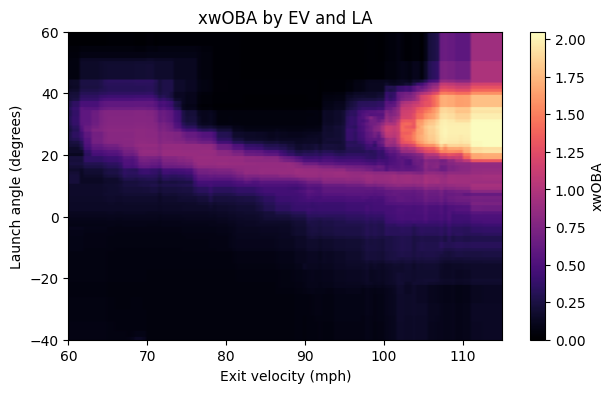

,"corr(xwOBAcon, next wOBAcon)","corr(wOBAcon, next wOBAcon)",spread of xwOBAcon,spread of wOBAcon
transition,,,,
half 1 -> half 2,0.494,0.381,0.057,0.069
half 2 -> half 3,0.472,0.400,0.065,0.076
half 3 -> half 4,0.501,0.410,0.060,0.070


In [27]:
# Fitted on half 1 alone: one half carries enough batted balls for the surface to settle,
# and half 1 is strictly before every target this project fits or scores.
import surface as S

bip = S.build_bip(statcast)
surf = S.fit_surface(bip)
ph_xw = S.attach(player_half, bip, surf)

# Heatmap of the surface
H = S.heatmap(surf)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(H.values, origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=2.05,
               extent=[H.columns[0], H.columns[-1], H.index[0], H.index[-1]])
fig.colorbar(im, ax=ax, label="xwOBA")
ax.set(xlabel="Exit velocity (mph)", ylabel="Launch angle (degrees)",
       title="xwOBA by EV and LA")
plt.show()

# Does the denoised numerator predict better? Correlate each half's numerator with the NEXT
# half's observed contact value, over hitters with 25+ balls in play in both halves.
con = ph_xw[ph_xw["nBIP"] >= 25].copy()
con["xwOBAcon"] = con["nXWcon"] / con["nBIP"]
con["wOBAcon"] = con["nWcon"] / con["nBIP"]

rows = []
for t in (1, 2, 3):
    this_half = con[con["SeasonID"] == t].set_index("BatterID")
    next_half = con[con["SeasonID"] == t + 1].set_index("BatterID")
    both = this_half.index.intersection(next_half.index)

    expected = this_half.loc[both, "xwOBAcon"]
    observed = this_half.loc[both, "wOBAcon"]
    target = next_half.loc[both, "wOBAcon"]

    rows.append({"transition": f"half {t} -> half {t + 1}",
                 "corr(xwOBAcon, next wOBAcon)": expected.corr(target),
                 "corr(wOBAcon, next wOBAcon)": observed.corr(target),
                 "spread of xwOBAcon": expected.std(),
                 "spread of wOBAcon": observed.std()})

pd.DataFrame(rows).set_index("transition").round(3)

We can see from the heatmap above that valuable contact is a narrow ridge. There is an island at 105-115 mph and 20-40 degrees representing home runs, and a ridge at 10-20 degrees representing line drives at any speed. Popups and grounders are worth little at any speed.

It is also apparant from the correlations that wxOBAcon is a better predictor of future wOBAcon than wOBAcon.

In [28]:
STAGE_XW = {"cats": ["nXWcon"],          # history pools EXPECTED contact value
            "act_cats": ["nWcon"],       # the target half is scored on OBSERVED value
            "denom": "nBIP",
            "features": {}, "feat_cols": [],
            "phi_grid": [10],            
            "green": 25}

STAGE_OBS = dict(STAGE_XW)               # the control, identical but for the next line
STAGE_OBS["cats"] = ["nWcon"]            # it pools OBSERVED value instead

shipped_fits = {}
for t in FOLDS:
    shipped_fits[t] = tuple(Tn.fit_all(ph_xw, t, fu, st) for fu, st in zip(FEATS, STAGES))

preds_xw = {"shipped: two-stage component model":
            E.project(ph_xw, FOLDS, shipped_fits, STAGES)["pred_wOBA"]}

# Three arms. The first two differ only in the numerator, which isolates what the surface is
# worth; the third adds greenness on top of the better one, so the last row is the best stage
# XW can do. The PA stage is held at its shipped fit throughout.
arms = [("observed value, flat prior", STAGE_OBS, []),
        ("expected value, flat prior", STAGE_XW, []),
        ("expected value + greenness", STAGE_XW, ["green"])]

for name, stage, feats in arms:
    category = stage["cats"][0][1:]                  # "XWcon" or "Wcon"
    fits = {}
    for t in FOLDS:
        contact = Tn.fit_all(ph_xw, t, {category: feats}, stage)
        fits[t] = (shipped_fits[t][0], contact)

    preds_xw[name] = E.project(ph_xw, FOLDS, fits, (STAGES[0], stage),
                               compose=E.compose_xwoba)["pred_wOBA"]

scores_xw = E.score(actual, pd.DataFrame(preds_xw).reindex(actual.index))
display(scores_xw.round(3))

target_half,2025 1H,2025 2H,mean,spread
shipped: two-stage component model,2.065,1.808,1.937,0.256
"observed value, flat prior",2.074,1.958,2.016,0.116
"expected value, flat prior",2.028,1.906,1.967,0.122
expected value + greenness,2.014,1.903,1.958,0.111


#### Verdict: Not shipped

The channel is better and the model is not. xwOBAcon predicts the next half's contact value at $r = 0.47$–$0.50$ against the observed numerator's own $0.38$–$0.41$, which is what makes it denoising rather than a change of target. Swapping the numerator and changing nothing else is worth 2.4% on the wOBA scale, 2.016 to 1.967, and greenness on top takes it to 1.958. That is still against the shipped 1.937, and the folds disagree in sign: it wins 2025 1H by 2.5% and loses 2025 2H by 5.2%.

The loss is structural rather than tuning. $\kappa$ sets how far a hitter is pulled toward $\mu$, not where $\mu$ sits, so it trades variance and cannot remove a bias. What stage XW discards is exactly a bias: the gap between what a hitter's contact was worth and what it should have been worth, from pull power into a short porch or speed out of the box. Losing this signal is why the model performs worse and is rejected

---
### The nested contact stage

Split the ball in play in two instead of resolving it five ways at once: home run or not, then a closed four-way choice among the balls that stayed in the park.

$$p_{HR} = \pi_{BIP}\,\theta_{HR}, \qquad p_x = \pi_{BIP}\,(1 - \theta_{HR})\,\psi_x,
\qquad x \in \{1B,\, 2B,\, 3B,\, OUT\}$$

What a stage boundary buys is a denominator, not a separate $\kappa$, since the estimator already gives every category one of those. The claim under test is that a singles rate is better estimated among the balls that stayed in the park than among all of them, and asking costs 4 batted balls at the median (97 → 93). Both arms carry the same features, link and greenness, so the boundary is the only thing that varies, and an architecture change has to win both folds.

In [29]:
# The one column the nested arm needs: balls in play that stayed in the park. Derived here
# rather than in data.py, so deleting this section returns the shipped model exactly.
ph_nested = player_half.assign(nBIPnoHR=player_half["nBIP"] - player_half["nHR"])

# Both halves read the same seven candidates as STAGE_BIP, still denominated on nBIP
STAGE_HR = {"cats": ["nHR"],
            "denom": "nBIP",
            "features": STAGE_BIP["features"],
            "feat_cols": STAGE_BIP["feat_cols"],
            "phi_grid": STAGE_BIP["phi_grid"],
            "green": 25}

STAGE_4WAY = {"cats": ["n1B", "n2B", "n3B", "nOUT"],
              "denom": "nBIPnoHR",
              "features": STAGE_BIP["features"],
              "feat_cols": ["nBIP"] + STAGE_BIP["feat_cols"],
              "phi_grid": STAGE_BIP["phi_grid"],
              "green": 25}

# FEAT_USE_BIP's own picks, split across the two stages, so the boundary is the only thing
# being measured.
FEAT_USE_HR = {"HR": ["ev90", "air", "green"]}
FEAT_USE_4WAY = {"1B": ["pullair", "green"],
                 "2B": ["ev90", "green"],
                 "3B": [],
                 "OUT": ["ev90", "green"]}

NESTED_STAGES = (STAGE_PA, STAGE_HR, STAGE_4WAY)
NESTED_FEATS = (FEAT_USE_PA, FEAT_USE_HR, FEAT_USE_4WAY)

# The shipped model refit on the augmented panel. nBIPnoHR is a column no stage of it
# pools, so this row has to reproduce the validation section.
combined_fits = {}
nested_fits = {}
for t in FOLDS:
    combined_fits[t] = tuple(Tn.fit_all(ph_nested, t, fu, st)
                             for fu, st in zip(FEATS, STAGES))
    nested_fits[t] = tuple(Tn.fit_all(ph_nested, t, fu, st)
                           for fu, st in zip(NESTED_FEATS, NESTED_STAGES))

preds_nested = {
    "shipped: contact resolved five ways at once":
        E.project(ph_nested, FOLDS, combined_fits, STAGES)["pred_wOBA"],
    "nested: HR | BIP, then the other four":
        E.project(ph_nested, FOLDS, nested_fits, NESTED_STAGES,
                  compose=E.compose_nested)["pred_wOBA"]}

display(E.score(actual, pd.DataFrame(preds_nested).reindex(actual.index)).round(3))

# What the choice is worth where it actually matters, which is the submission itself.
combined_5 = E.compose_woba(player_half, TARGET, params, STAGES, holdout)["pred_wOBA"]
nested_5 = E.compose_nested(ph_nested, TARGET,
                            tuple(Tn.fit_all(ph_nested, TARGET, fu, st)
                                  for fu, st in zip(NESTED_FEATS, NESTED_STAGES)),
                            NESTED_STAGES, holdout)["pred_wOBA"]
print(f"the two submissions: correlation {combined_5.corr(nested_5):.4f}, "
      f"mean absolute difference {(combined_5 - nested_5).abs().mean():.4f}, "
      f"largest {(combined_5 - nested_5).abs().max():.4f}")

target_half,2025 1H,2025 2H,mean,spread
shipped: contact resolved five ways at once,2.065,1.808,1.937,0.256
"nested: HR | BIP, then the other four",2.043,1.808,1.925,0.235


the two submissions: correlation 0.9994, mean absolute difference 0.0008, largest 0.0043


#### Verdict: a tie, and a tie goes to the simpler model

The nested arm wins one fold and ties the other. The 0.6% mean gain is well inside the ~2% a single fold moves, so the improvement is likely noise. The evidence provided shows no justification for the additional complexity that breaking BIP into two stages adds.

The theory we tested the boundary for does not survive either. A home run was supposed to be the sharp break in reliability on contact, and it is not: $\kappa_{HR}$ and $\kappa_{3B}$ come out at 480 and 425, while the genuine 5× break sits inside the four-way split, 425 to 2166.

---
### Two smaller checks — a flat prior, and the other link functions

The flat arm deletes the feature priors, so $\mu$ becomes the league rate exactly. That drops the greenness term along with them, since greenness is a term in $\mu$, so these rows are what the whole prior is worth rather than the features alone. 

The alternate link replaces the logit link with a linear and binomial link function.

In [30]:
# One key changed, twice, and nothing else. Every fit above this cell carries no "link"
# at all and takes the default logit link.
STAGES_IDENTITY = (dict(STAGE_PA, link="identity"), dict(STAGE_BIP, link="identity"))
STAGES_BINOMIAL = (dict(STAGE_PA, link="binomial"), dict(STAGE_BIP, link="binomial"))

# no_features is the same helper the wOBA floor is built from: every category takes the
# league rate, so there is no beta to fit and no greenness to carry.
FLAT_PA = Tn.no_features(STAGE_PA["cats"])
FLAT_BIP = Tn.no_features(STAGE_BIP["cats"])

# The shipped row is the fit from the validation section, not a refit of it.
preds_small = {"shipped: feature prior, logit link": model}

arms = [("flat league prior at the PA stage",      (FLAT_PA, FEAT_USE_BIP), STAGES),
        ("flat league prior at the contact stage", (FEAT_USE_PA, FLAT_BIP), STAGES),
        ("flat league prior at both stages",       (FLAT_PA, FLAT_BIP),     STAGES),
        ("identity link at both stages",           FEATS, STAGES_IDENTITY),
        ("binomial link at both stages",           FEATS, STAGES_BINOMIAL)]

for name, feats, stages in arms:
    fits = {}
    for t in FOLDS:
        fits[t] = tuple(Tn.fit_all(player_half, t, fu, st) for fu, st in zip(feats, stages))
    preds_small[name] = E.project(player_half, FOLDS, fits, stages)["pred_wOBA"]

display(E.score(actual, pd.DataFrame(preds_small).reindex(actual.index)).round(3))

# The half of the link argument the ladder cannot make. Refit at the target half and look at
# the home-run prior the identity link hands the holdout hitters in the deliverable: a hitter with
# mu <= 0 and no home runs in his history gets theta = 0 exactly, an impossible rate.
params_identity = tuple(Tn.fit_all(player_half, TARGET, fu, st)
                        for fu, st in zip(FEATS, STAGES_IDENTITY))
for name, prm, stg in [("logit   ", params_BIP, STAGE_BIP),
                       ("identity", params_identity[1], STAGES_IDENTITY[1])]:
    hr = M.predict(player_half, TARGET, prm, stg, players=holdout)
    hr = hr[hr["cat"] == "HR"]
    print(f"{name} link, HR prior over the {len(hr)} holdout hitters: "
          f"mu from {hr['mu_i'].min():.5f} to {hr['mu_i'].max():.5f}, "
          f"{(hr['mu_i'] <= 0).sum()} at or below zero, "
          f"{(hr['pred'] <= 0).sum()} projected to .000")

target_half,2025 1H,2025 2H,mean,spread
"shipped: feature prior, logit link",2.065,1.808,1.937,0.256
flat league prior at the PA stage,2.101,1.846,1.973,0.254
flat league prior at the contact stage,2.045,1.919,1.982,0.125
flat league prior at both stages,2.093,1.959,2.026,0.134
identity link at both stages,2.060,1.819,1.940,0.241
binomial link at both stages,2.007,1.809,1.908,0.197


logit    link, HR prior over the 586 holdout hitters: mu from 0.00956 to 0.14911, 0 at or below zero, 0 projected to .000
identity link, HR prior over the 586 holdout hitters: mu from -0.02414 to 0.10822, 2 at or below zero, 2 projected to .000


#### Verdict: both kept

---
## Player dive

One table. `projection_table` puts the eight predicted per-PA probabilities beside the eight observed per-PA rates, so a projection reads directly against what the hitter did on the same scale.

Names and handedness come from `data.build_people` rather than from the panel, because a hitter with no history has no panel row at all — 71 of the 586 — and would otherwise lose his name in exactly the table meant to account for him.

In [31]:
# Projections for the target half, 2026 1H
dive = E.projection_table(player_half, TARGET, params, STAGES, holdout, people)
dive.sort_values("pred_wOBA", ascending=False).head(10)[
    ["PlayerName", "Bats", "p_K", "p_BB", "p_HR", "p_1B", "p_2B", "pred_wOBA"]].round(3)

,PlayerName,Bats,p_K,p_BB,p_HR,p_1B,p_2B,pred_wOBA
BatterID,,,,,,,,
592450,Aaron Judge,R,0.252,0.172,0.079,0.116,0.044,0.451
660271,Shohei Ohtani,L,0.249,0.123,0.072,0.121,0.046,0.415
670541,Yordan Álvarez,L,0.159,0.106,0.062,0.149,0.053,0.411
665742,Juan Soto,L,0.184,0.172,0.055,0.129,0.044,0.409
665489,Vladimir Guerrero,R,0.150,0.108,0.044,0.166,0.057,0.390
677951,Bobby Witt,R,0.171,0.076,0.047,0.161,0.058,0.386
606466,Ketel Marte,S,0.171,0.109,0.052,0.143,0.049,0.382
656941,Kyle Schwarber,L,0.284,0.145,0.062,0.103,0.039,0.378
663656,Kyle Tucker,L,0.159,0.146,0.045,0.133,0.042,0.373


In [32]:
# The same table at a half that HAS been played (2025 2H), so the actuals fill in and `resid` is pred
# minus actual on the wOBA scale.
back = E.projection_table(player_half, 4, fit_by_T[4], STAGES,
                          player_half.loc[player_half["SeasonID"] == 4, "BatterID"],
                          people)
back[back["nPA"] >= 200].sort_values(by = "resid", key=abs, ascending=False) \
    .reset_index(drop=True)[["target_half", "PlayerName", "Bats", "nPA", "pred_wOBA", "act_wOBA", "resid"]] \
    .round(3).head(10)

,target_half,PlayerName,Bats,nPA,pred_wOBA,act_wOBA,resid
0,4,Nick Kurtz,L,302,0.316,0.462,-0.146
1,4,George Springer,R,280,0.330,0.467,-0.137
2,4,Bo Bichette,R,249,0.316,0.427,-0.112
3,4,Oneil Cruz,L,219,0.348,0.255,0.094
4,4,Geraldo Perdomo,S,354,0.319,0.397,-0.078
5,4,Agustín Ramírez,R,336,0.355,0.278,0.077
6,4,Jakob Marsee,L,234,0.290,0.364,-0.074
7,4,Roman Anthony,L,230,0.327,0.400,-0.073
8,4,Kyle Tucker,L,227,0.383,0.310,0.073
9,4,Harrison Bader,R,264,0.298,0.370,-0.072
